
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/13_Lab_PinnsII.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pylab as plt
import plotly.graph_objects as go

#Diferenciación automática

In [3]:
def suma(a, da, b, db):
  return a+b, da+db

def producto(a, da, b, db):
  return a*b, a*db + da*b

def division(a, da, b, db):
  return a/b, (b*da - a*db)/(b**2)

def seno(a, da):
  return np.sin(a), da*np.cos(a)

def coseno(a, da):
  return np.cos(a), -da*np.sin(a)


def tanhiperbolica(a, da):
    valor = np.tanh(a)
    return valor, (1 - valor**2)*da


def tanhiperbolica2(a, da, d2a):
    A, dA = tanhiperbolica(a, da)
    A2, dA2 = producto(A, dA, A, dA)
    G, dG = suma(1, 0, -A2, -dA2)
    _, d2A = producto(G, dG, da, d2a)
    return A, dA, d2A

Computemos la deriva de:

$f(x) = x^2$


$f(x) = (2x+1)^2$

In [4]:
x = 2.2

In [5]:
derivadaX = producto(x, 1, x, 1)
derivadaX

(4.840000000000001, 4.4)

In [6]:
u, du = producto(2, 0, x, 1)
c, dc = suma(u, du, 1, 0)
producto(c, dc, c, dc)

(29.160000000000004, 21.6)

In [7]:
x = np.linspace(0, 2*np.pi)

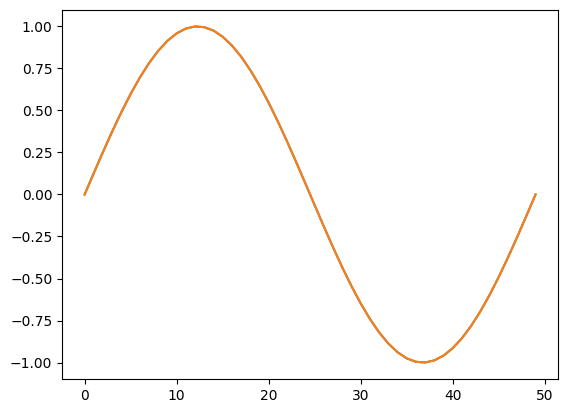

In [8]:
plt.plot(np.sin(x))
plt.plot(seno(x, 1)[0])

$
f(x)=\sin\!\bigl(\cos(x^2)\bigr),
$

$
u=x^2,\qquad u'=2x,
$

$
v=\cos(u),\qquad v'=-\sin(u)\,u',
$


$
f=\sin(v),\qquad f'=\cos(v)\,v'.
$


$
f'(x)=-2x\,\sin(x^2)\,\cos\!\bigl(\cos(x^2)\bigr).
$

In [9]:
x = np.linspace(0, 2*np.pi, 10000)
u, du = producto(x, 1, x, 1)
c, dc = coseno(u, du)
r, dr = seno(c, dc)

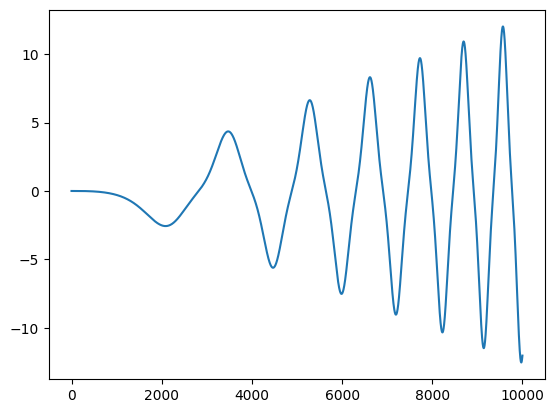

In [10]:
plt.plot(dr)

Supongamos que tenemos dos conectadas y queremos computar una diferenciacion automática cuyas funciones de activación son tanh:

\begin{equation}
\frac{da_2}{dx}
=
\frac{da_2}{dz_2}
\frac{dz_2}{da_1}
\frac{da_1}{dz_1}
\frac{dz_1}{dx}
=
(1-\tanh Z_2^2)\,w_2\,(1-\tanh Z_1^2)\,w_1.
\end{equation}



In [11]:
x = 0.8
w = 0.1
b = 0.1

z = w*x + b
a1 = np.tanh(z)

z2 = w*a1 + b
a2 = np.tanh(z2)

derivada = (1-(np.tanh( z2))**2) * (1-(np.tanh( z))**2)*w**2
derivada

np.float64(0.009549719627467191)

In [12]:
t1, dt1 = producto(w, 0, x, 1)
z, dz = suma(t1, dt1, b, 0)
a1, da1 = tanhiperbolica(z, dz)

t2, dt2 = producto(w, 0, a1, da1)
z2, dz2 = suma(t2, dt2, b, 0)
a2, da2 = tanhiperbolica(z2, dz2)
a2, da2




(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

In [13]:
def dneurona(x, dx, w, b):
  t1, dt1 = producto(w, 0, x, dx)
  z, dz = suma(t1, dt1, b, 0)
  a1, da1 = tanhiperbolica(z, dz)
  return a1, da1

In [14]:
a1, da1 = dneurona(x, 1, w, b)
a2, da2 = dneurona(a1, da1, w, b)
a2, da2

(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

### Difusión de calor en una placa cuadrada

Considere una placa homogénea de lado $L$, sin fuentes internas
de calor y con temperatura uniforme a través de su espesor.
Su difusividad térmica es constante:

$$
\alpha=\frac{k}{\rho c_p},
$$

donde $k$ es la conductividad térmica, $\rho$ la densidad y
$c_p$ el calor específico.

Determine la temperatura $T(x,y,t)$ en el dominio
$(x,y)\in(0,L)^2$, para $t>0$, mediante la ecuación de calor:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2T}{\partial x^2}
+
\frac{\partial^2T}{\partial y^2}
\right).
$$

Los cuatro bordes permanecen a temperatura constante $T_b$:

$$
T(0,y,t)=T(L,y,t)=T(x,0,t)=T(x,L,t)=T_b.
$$

La temperatura inicial es:

$$
T(x,y,0)=T_b+\Delta T
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right),
$$

donde $\Delta T>0$ es la diferencia inicial entre la temperatura
del centro y la de los bordes.

Aproximar $T(x,y,t)$ mediante una PINN,
minimizando el residual de la ecuación y los errores en las
condiciones iniciales y de frontera. Comparar el resultado
con la solución analítica:

$$
T(x,y,t)=T_b+\Delta T
e^{-2\alpha\pi^2t/L^2}
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right).
$$

In [15]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [16]:
def T(x, y, t, **params):

  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + delta_T* np.exp(-2*alpha*np.pi**2*t/(Lx*Ly))*u


In [17]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

In [18]:
def Temp_border():
  for k in range(0, nt):
    for i   in range(0, nx):
      for j in range(0, ny):
        if(i == 0):
          Temperatura[k][0, j] = Tb
        elif(j == 0):
          Temperatura[k][i, 0] = Tb
        elif(i == nx-1):
          Temperatura[k][nx-1, j] = Tb
        elif(j == ny-1):
          Temperatura[k][i, ny-1] = Tb
        else:
          Temperatura[k][i, j] = 0
  return Temperatura

In [19]:
#x = np.linspace(0, 1, 100)
#y = np.linspace(0, 1, 100)
#t = np.linspace(0, 800, 1000)

X, Y = np.meshgrid(x, y, indexing="ij")
Temperatura = Temp_border()
Temperatura[0,:,:] =  T(X, Y, 0, **params)

In [20]:
np.min(Temperatura[0])

np.float64(300.0)

In [21]:
np.max(Temperatura[0,:,:])

np.float64(399.706897857718)

In [22]:
import numpy as np
import plotly.graph_objects as go


def graficar_planos(
    Temperatura, Lx, Ly,
    tiempos=None,
    n_planos=5,
    opacidad=0.5
):
    nt, nx, ny = Temperatura.shape

    x = np.linspace(0, Lx, nx)
    y = np.linspace(0, Ly, ny)
    X, Y = np.meshgrid(x, y, indexing="ij")

    titulo_t = "Tiempo [s]" if tiempos is not None else "Índice de tiempo"
    tiempos = np.arange(nt) if tiempos is None else np.asarray(tiempos)

    # Seleccionar pocos tiempos, incluyendo el primero y el último.
    indices = np.unique(
        np.linspace(0, nt - 1, min(n_planos, nt), dtype=int)
    )

    # Escala de colores común.
    Tmin = float(np.nanmin(Temperatura))
    Tmax = float(np.nanmax(Temperatura))

    if Tmin == Tmax:
        Tmin -= 0.5
        Tmax += 0.5

    fig = go.Figure()

    for j, k in enumerate(indices):
        fig.add_trace(go.Surface(
            x=np.full(X.shape, tiempos[k], dtype=float),
            y=X,
            z=Y,
            surfacecolor=Temperatura[k],
            colorscale="Jet",
            cmin=Tmin,
            cmax=Tmax,
            opacity=opacidad,
            showscale=(j == 0),
            colorbar=dict(title="Temperatura [°C]"),
            lighting=dict(ambient=1, diffuse=0, specular=0),
            name=f"Temperatura[{k}]",
            hovertemplate=(
                "Tiempo / índice = %{x:.3f}<br>"
                "x = %{y:.3f} m<br>"
                "y = %{z:.3f} m<br>"
                "T = %{surfacecolor:.2f} °C"
                "<extra>%{fullData.name}</extra>"
            )
        ))

    fig.update_layout(
        height=650,
        scene=dict(
            xaxis_title=titulo_t,
            yaxis_title="x [m]",
            zaxis_title="y [m]",
            aspectmode="manual",
            aspectratio=dict(x=1.6, y=1, z=Ly / Lx),
            camera=dict(eye=dict(x=-1.7, y=-1.7, z=0.8))
        ),
        margin=dict(l=0, r=0, b=0, t=30)
    )

    return fig

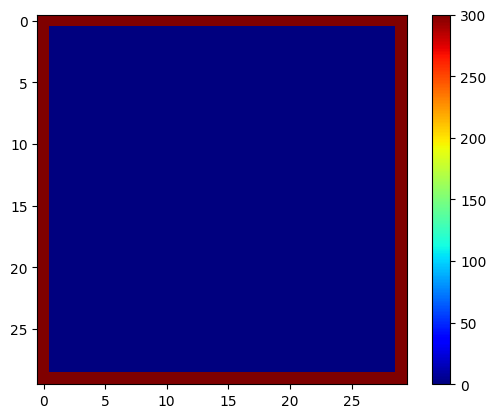

In [23]:
plt.imshow(Temperatura[1], cmap='jet')
plt.colorbar()
plt.show()

In [24]:
for i in range(1, len(t)):
  Temperatura[i,:,:] =  T(X, Y, t[i], **params)

In [25]:
fig = graficar_planos(
    Temperatura, Lx, Ly,
    n_planos=10,
    opacidad=0.5
)
fig.show()

In [26]:
np.shape(Temperatura)

(188, 30, 30)

In [27]:
n_frames =len(Temperatura)# min(100), Temperatura.shape[0])
n_frames

188

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

n_frames =len(Temperatura)# min(100), Temperatura.shape[0])

fig, ax = plt.subplots(figsize=(6, 5))

imagen = ax.imshow(
    Temperatura[0],
    cmap="jet",
    vmin=np.nanmin(Temperatura[:n_frames]),
    vmax=np.nanmax(Temperatura[:n_frames])
)

fig.colorbar(imagen, ax=ax, label="Temperatura [°C]")
titulo = ax.set_title("Temperatura[0]")

def actualizar(i):
    imagen.set_data(Temperatura[i])
    titulo.set_text(f"Temperatura[{i}]")
    return imagen, titulo

animacion = FuncAnimation(
    fig,
    actualizar,
    frames=n_frames,
    interval=1,
    repeat=True
)

plt.close(fig)
display(HTML(animacion.to_jshtml()))

Output hidden; open in https://colab.research.google.com to view.


# Physics-Informed Machine Learning (PIML)

Consideremos la ecuación de difusión de calor en dos dimensiones:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2 T}{\partial x^2}
+
\frac{\partial^2 T}{\partial y^2}
\right),
$$

donde $\alpha$ es la difusividad térmica.

## 1. Modelo neuronal con tangente hiperbólica

Consideremos una neurona definida por:

$$
Z_\theta(x,y,t)=\theta_1 x+\theta_2 y+\theta_3 t+b.
$$

La temperatura se aproxima mediante:

$$
T_\theta(x,y,t)=\tanh(Z_\theta).
$$

## 2. Modelo neuronal con activación gaussiana

Conservando una sola neurona, podemos incorporar una dependencia espacial cuadrática:

$$
Z_\theta(x,y,t)=
\theta_1(x-x_c)^2+
\theta_2(y-y_c)^2+
\theta_3t+b.
$$

La temperatura se aproxima mediante:

$$
T_\theta(x,y,t)=e^{-Z_\theta}.
$$

Esta función permite representar distribuciones localizadas de temperatura, con un máximo espacial cuando los coeficientes cuadráticos son positivos.

## 3. Función de coste física

Para cualquiera de los dos modelos, definimos el residuo:

$$
R_\theta(x_i,y_i,t_i)=
\frac{\partial T_\theta}{\partial t}
-
\alpha\left(
\frac{\partial^2T_\theta}{\partial x^2}
+
\frac{\partial^2T_\theta}{\partial y^2}
\right).
$$

La función de coste es:

$$
J_{\mathrm{fisica}}(\theta)=
\frac{1}{M}\sum_{i=1}^{M}
R_\theta(x_i,y_i,t_i)^2.
$$

Las derivadas se calculan mediante diferenciación automática.

## 4. Condiciones iniciales y de frontera

Si conocemos las temperaturas iniciales y de frontera, incorporamos sus errores:

$$
J(\theta)=
J_{\mathrm{fisica}}
+
J_{\mathrm{inicial}}
+
J_{\mathrm{frontera}}.
$$

Finalmente, los parámetros se actualizan mediante descenso de gradiente:

$$
\theta^{(k+1)}
=
\theta^{(k)}
-\eta\nabla_\theta J.
$$

Ambos modelos tienen cuatro parámetros entrenables: tres pesos y un sesgo. La diferencia principal está en la función utilizada para representar el campo de temperaturas.


Para entrenar la red construiremos un vector de entrada como sigue:
https://www.sciencedirect.com/science/article/pii/S0021999118307125

\begin{equation}
\mathbf Q=
\begin{pmatrix}
x_1&y_1&t_0\\
x_2&y_2&t_0\\
\vdots&\vdots&\vdots\\
x_N&y_N&t_0
\end{pmatrix}
\end{equation}




In [29]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [30]:
def T(x, y, t, **params):
  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + delta_T* np.exp(-2*alpha*np.pi**2*t/(Lx*Ly))*u


In [31]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

In [32]:
def Temp_border():
  for k in range(0, nt):
    for i   in range(0, nx):
      for j in range(0, ny):
        if(i == 0):
          Temperatura[k][0, j] = Tb
        elif(j == 0):
          Temperatura[k][i, 0] = Tb
        elif(i == nx-1):
          Temperatura[k][nx-1, j] = Tb
        elif(j == ny-1):
          Temperatura[k][i, ny-1] = Tb
        else:
          Temperatura[k][i, j] = 0
  return Temperatura

In [33]:
tf = np.max(t) - np.min(t)
tf

np.float64(500.0)

In [34]:
#x = np.linspace(0, 1, 100)
#y = np.linspace(0, 1, 100)
#t = np.linspace(0, 800, 1000)
X, Y = np.meshgrid(x, y, indexing="ij")
Temperatura = Temp_border()
Temperatura[0,:,:] =  T(X, Y, 0, **params)


In [35]:
X1 = x.reshape((len(x), 1))
Y1 = y.reshape((len(y), 1))
tk = t.reshape((len(t), 1))/np.max(t)

In [36]:
Q=np.zeros((30*30*nt, 3))
p=0
for k in range(0, nt):
  for i in range(0, nx):
    for j in range(0, ny):
      Q[p] = np.array([ t[k],x[i], y[j]])
      p=p+1

# Selección de los bordes

In [37]:
tt = Q[:,0].reshape(nt, nx, ny)
xx = Q[:,1].reshape(nt, nx, ny)
yy = Q[:,2].reshape(nt, nx, ny)
borde = (
    np.isclose(xx, x[0]) |
    np.isclose(xx, x[-1]) |
    np.isclose(yy, y[0]) |
    np.isclose(yy, y[-1])
)
borde_concatenado = borde.reshape(-1)

In [38]:
Q_borde = Q[borde_concatenado]
Q_borde

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 3.44827586e-02],
       [0.00000000e+00, 0.00000000e+00, 6.89655172e-02],
       ...,
       [5.00000000e+02, 1.00000000e+00, 9.31034483e-01],
       [5.00000000e+02, 1.00000000e+00, 9.65517241e-01],
       [5.00000000e+02, 1.00000000e+00, 1.00000000e+00]], shape=(21808, 3))

In [39]:
T_borde = Temperatura[borde].reshape(-1, 1)
print(Q_borde.shape)
print(T_borde.shape)

(21808, 3)
(21808, 1)


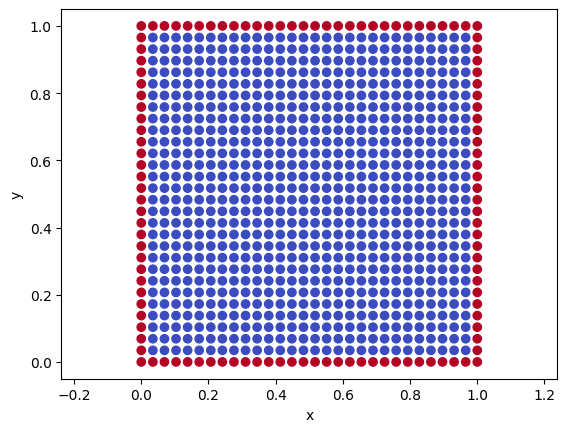

In [40]:
plt.scatter(xx[0], yy[0], c=borde[0], cmap="coolwarm")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.show()

## Condicion inicial

In [41]:
inicial = np.isclose(tt, t[0])
Q_ini = Q[inicial.reshape(-1)]
T_ini = Temperatura[inicial].reshape(-1, 1)
print(Q_ini.shape)
print(T_ini.shape)

(900, 3)
(900, 1)


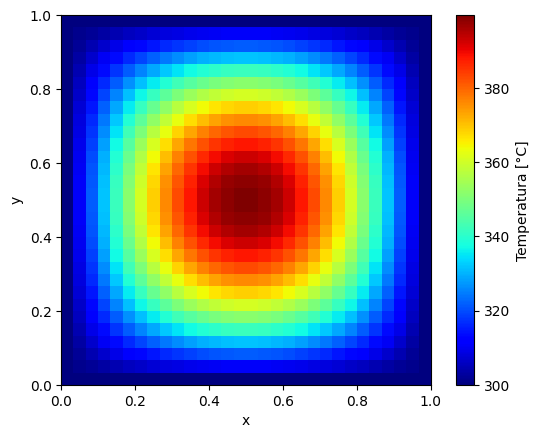

In [42]:
plt.imshow(
    Temperatura[0].T,
    origin="lower",
    extent=[x[0], x[-1], y[0], y[-1]],
    cmap="jet"
)

plt.colorbar(label="Temperatura [°C]")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [43]:
#Normalizacion
delta_T = max(np.max(np.abs(T_ini - Tb)), 1.0)
u_ini = (T_ini - Tb) / delta_T
u_borde = (T_borde - Tb) / delta_T

In [44]:
interior = ~borde & ~inicial

Q_f = Q[interior.reshape(-1)]

In [45]:
# Inicialización
np.random.seed(42)

perdidas = []
eta = 0.01

W = np.random.random((3, 1))
B = np.random.random((1, 1))

# Derivadas de Z respecto a (wt, wx, wy, b)
dZ = np.column_stack((Q_f, np.ones(len(Q_f))))
dZ_ini = np.column_stack((Q_ini, np.ones(len(Q_ini))))
dZ_borde = np.column_stack((Q_borde, np.ones(len(Q_borde))))

et = np.array([1, 0, 0, 0])

for i in range(1000):
    if(i%50==0):
      print(i)

    # Forward
    Z = Q_f @ W + B
    A = np.tanh(Z)

    # Derivadas
    _, dA_dt, _ = tanhiperbolica2(Z, W[0, 0], 0)
    _, _, d2A_dx2 = tanhiperbolica2(Z, W[1, 0], 0)
    _, _, d2A_dy2 = tanhiperbolica2(Z, W[2, 0], 0)
    R = dA_dt - alpha * (d2A_dx2 + d2A_dy2)
    J_fisica = np.mean(R**2)

    # Derivadas de tanh respecto a Z
    A, G, H = tanhiperbolica2(Z, 1, 0)
    _, K = producto(-2*A, -2*G, G, H)

    # Pesos
    wt, wx, wy = W[:, 0]

    # Gradientes del residuo
    C = wt*H - alpha*(wx**2 + wy**2)*K

    dR = C*dZ

    dR[:, 0] += G[:, 0]
    dR[:, 1] -= 2*alpha*wx*H[:, 0]
    dR[:, 2] -= 2*alpha*wy*H[:, 0]

    # Gradiente de la función de coste
    gradiente = np.mean(2*R*dR, axis=0)

    # Condición inicial
    A_ini = np.tanh(Q_ini @ W + B)
    J_ini = np.mean((A_ini - u_ini)**2)
    ei = (A_ini - u_ini) * (1 - A_ini**2)
    gradiente += 2*np.mean(ei*dZ_ini, axis=0)

    # Condiciones de frontera
    A_borde = np.tanh(Q_borde @ W + B)
    J_borde = np.mean((A_borde - u_borde)**2)
    eb = (A_borde - u_borde) * (1 - A_borde**2)
    gradiente += 2*np.mean(eb*dZ_borde, axis=0)

    # Función de coste total
    J = J_fisica + J_ini + J_borde

    # Actualización de los parámetros
    W[:, 0] -= eta * gradiente[:3]
    B[0, 0] -= eta * gradiente[3]

    perdidas.append(J)

0
50
100
150
200
250
300
350
400
450
500
550
600
650
700
750
800
850
900
950


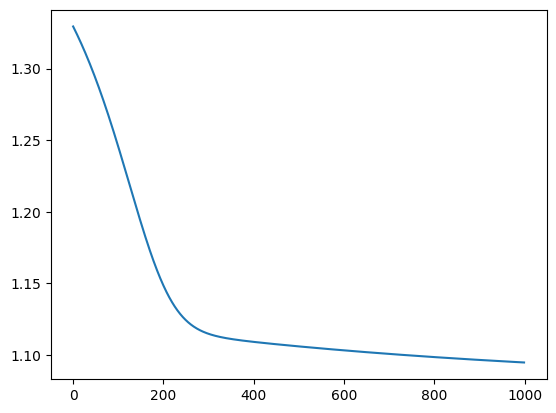

In [46]:
plt.plot(np.array(perdidas))
perdidas_tanh = list(perdidas)

In [47]:
Z = Q@W+B
A = np.tanh(Z)
Temperatura_PINN = Tb + delta_T*A.reshape(nt, nx, ny)
Temperatura_tanh = Temperatura_PINN.copy()

In [48]:
A = A.reshape(nx, ny,nt)

In [49]:

fig = graficar_planos(
    Temperatura_PINN,
    Lx,
    Ly,
    tiempos=t,
    n_planos=5
)

fig.show()

In [50]:
# Implementar el mismo codigo para una funcion de la forma:
#

In [51]:
def caracteristicas(Q):
    tau = (Q[:, 0:1] - t[0]) / tf
    xi = (Q[:, 1:2] - x[0]) / Lx - 0.5
    yi = (Q[:, 2:3] - y[0]) / Ly - 0.5

    P = np.hstack((tau, xi**2, yi**2))

    return P, xi, yi

P, xi, yi = caracteristicas(Q)
P_ini, _, _ = caracteristicas(Q_ini)
P_borde, _, _ = caracteristicas(Q_borde)

In [52]:
W = np.random.random((3, 1))
B = np.random.random((1, 1))

Z = P @ W + B
A = np.exp(-Z)

In [53]:
def exponencial(a, da):
    A = np.exp(a)
    return A, A*da

def exponencial2(a, da, d2a):
    A, dA = exponencial(a, da)
    _, d2A = producto(A, dA, da, d2a)
    return A, dA, d2A

In [54]:
wt, wx, wy = W[:, 0]

_, dA_dt, _ = exponencial2(-Z, -wt, 0)

_, _, d2A_dx2 = exponencial2(
    -Z, -2*wx*xi, -2*wx
)

_, _, d2A_dy2 = exponencial2(
    -Z, -2*wy*yi, -2*wy
)

In [55]:
ax = alpha * tf / Lx**2
ay = alpha * tf / Ly**2

R = dA_dt - ax*d2A_dx2 - ay*d2A_dy2

J_fisica = np.mean(R**2)

In [56]:
np.random.seed(42)

W = np.random.random((3, 1))
B = np.random.random((1, 1))

eta = 0.01
perdidas = []

ax = alpha * tf / Lx**2
ay = alpha * tf / Ly**2

dZ = np.column_stack((P, np.ones(len(P))))
dZ_ini = np.column_stack((P_ini, np.ones(len(P_ini))))
dZ_borde = np.column_stack((P_borde, np.ones(len(P_borde))))

et, ex, ey = np.eye(4)[:3]

for i in range(1000):

    # Forward
    Z = P @ W + B
    A = np.exp(-Z)

    wt, wx, wy = W[:, 0]

    # Derivadas automáticas respecto a las coordenadas
    _, dA_dt, _ = exponencial2(-Z, -wt, 0)

    _, _, d2A_dx2 = exponencial2(
        -Z, -2*wx*xi, -2*wx
    )

    _, _, d2A_dy2 = exponencial2(
        -Z, -2*wy*yi, -2*wy
    )

    R = dA_dt - ax*d2A_dx2 - ay*d2A_dy2
    J_fisica = np.mean(R**2)

    # Gradientes del residuo respecto a W y B
    px, dpx = producto(2*xi, 0, wx, ex)
    py, dpy = producto(2*yi, 0, wy, ey)

    Fx, dFx = producto(px, dpx, px, dpx)
    Fx, dFx = suma(Fx, dFx, -2*wx, -2*ex)

    Fy, dFy = producto(py, dpy, py, dpy)
    Fy, dFy = suma(Fy, dFy, -2*wy, -2*ey)

    C, dC = suma(-wt, -et, -ax*Fx, -ax*dFx)
    C, dC = suma(C, dC, -ay*Fy, -ay*dFy)

    _, dR = producto(A, -A*dZ, C, dC)

    gradiente = np.mean(2*R*dR, axis=0)

    # Condición inicial
    A_ini = np.exp(-(P_ini @ W + B))

    J_ini = np.mean((A_ini - u_ini)**2)

    ei = (A_ini - u_ini) * (-A_ini)
    gradiente += 2*np.mean(ei*dZ_ini, axis=0)

    # Condición de frontera
    A_borde = np.exp(-(P_borde @ W + B))

    J_borde = np.mean((A_borde - u_borde)**2)

    eb = (A_borde - u_borde) * (-A_borde)
    gradiente += 2*np.mean(eb*dZ_borde, axis=0)

    # Coste total
    J = J_fisica + J_ini + J_borde
    perdidas.append(J)

    # Actualizar parámetros
    W[:, 0] -= eta*gradiente[:3]
    B[0, 0] -= eta*gradiente[3]

    if i % 50 == 0:
        print(i, J)

0 0.20794333370467535
50 0.16953420784536372
100 0.1524483378853501
150 0.14333168240336175
200 0.13790447188370888
250 0.13442161282876935
300 0.13205678759894374
350 0.13037641605880035
400 0.12913526140946588
450 0.12818644528168052
500 0.12743794867553102
550 0.12682999497542846
600 0.1263225822810427
650 0.12588827265537395
700 0.12550785111114748
750 0.1251676218979046
800 0.12485767476402859
850 0.1245707448160829
900 0.12430144606265495
950 0.12404574611832306


In [57]:
A = np.exp(-(P @ W + B))

Temperatura_PINN = Tb + delta_T*A.reshape(nt, nx, ny)

fig = graficar_planos(
    Temperatura_PINN,
    Lx,
    Ly,
    tiempos=t,
    n_planos=5
)

fig.show()

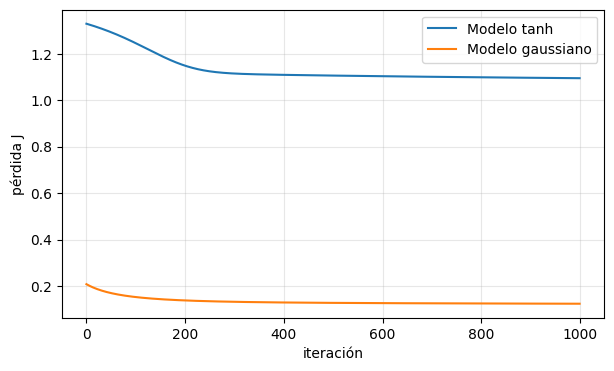

tanh: error máx = 99.7 °C | error medio = 75.4 °C
gaussiano: error máx = 66.8 °C | error medio = 14.4 °C


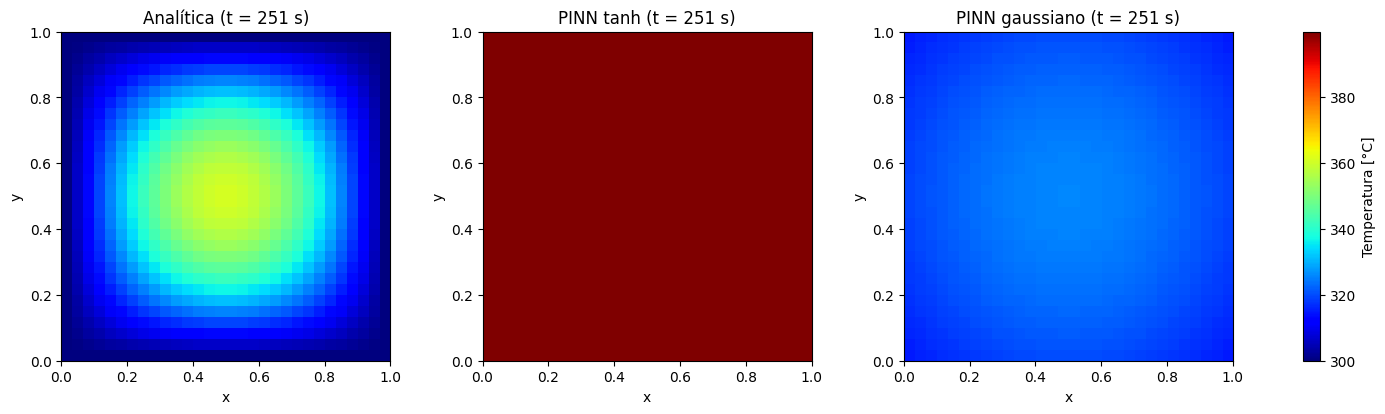

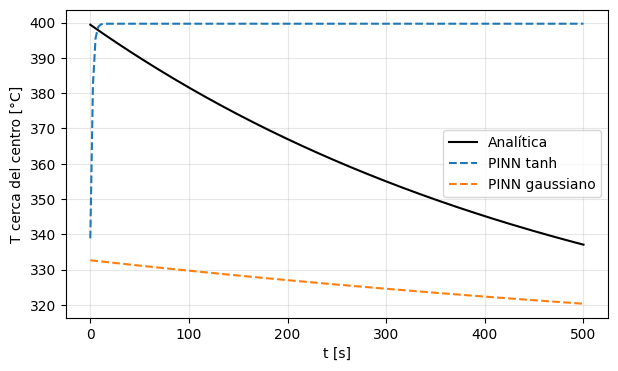

In [58]:
Temperatura_gauss = Temperatura_PINN.copy()      # resultado del modelo gaussiano
perdidas_gauss = list(perdidas)

# Solución analítica en la misma malla
T_exacta = np.array([T(X, Y, tk, **params) for tk in t])

# 1) Curvas de pérdida de los dos modelos
plt.figure(figsize=(7, 4))
plt.plot(perdidas_tanh, label="Modelo tanh")
plt.plot(perdidas_gauss, label="Modelo gaussiano")
plt.xlabel("iteración"); plt.ylabel("pérdida J"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# 2) Error de cada modelo contra la solución analítica
for nombre, TP in [("tanh", Temperatura_tanh), ("gaussiano", Temperatura_gauss)]:
    e = np.abs(TP - T_exacta)
    print(f"{nombre}: error máx = {e.max():.1f} °C | error medio = {e.mean():.1f} °C")

# 3) Mapas a mitad del tiempo: analítica vs cada modelo
k = nt // 2
campos = [("Analítica", T_exacta[k]), ("PINN tanh", Temperatura_tanh[k]), ("PINN gaussiano", Temperatura_gauss[k])]
fig, axs = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, (titulo, campo) in zip(axs, campos):
    im = ax.imshow(campo.T, origin="lower", cmap="jet", vmin=Tb, vmax=Tb + delta_T, extent=[0, Lx, 0, Ly])
    ax.set_title(f"{titulo} (t = {t[k]:.0f} s)")
    ax.set_xlabel("x"); ax.set_ylabel("y")
fig.colorbar(im, ax=axs, label="Temperatura [°C]")
plt.show()

# 4) Temperatura cerca del centro en función del tiempo
ic, jc = nx // 2, ny // 2
plt.figure(figsize=(7, 4))
plt.plot(t, T_exacta[:, ic, jc], "k-", label="Analítica")
plt.plot(t, Temperatura_tanh[:, ic, jc], "--", label="PINN tanh")
plt.plot(t, Temperatura_gauss[:, ic, jc], "--", label="PINN gaussiano")
plt.xlabel("t [s]"); plt.ylabel("T cerca del centro [°C]"); plt.legend(); plt.grid(alpha=0.3)
plt.show()